<a href="https://colab.research.google.com/github/sohailpk84-max/pakgeek/blob/main/Synthetic_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install sdv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.4/215.4 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 69.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.3/259.3 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 56.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 5.3 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sdv.single_table import CTGANSynthesizer
from sdv.metadata import SingleTableMetadata
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

import warnings

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [ ]:
# Load the dataset
from google.colab import files
uploaded = files.upload()
file_path = "kidney_disease.csv"
data = pd.read_csv(file_path)
#######################################
# Rename columns for clarity
column_mapping = {
    'age': 'age',
    'bp': 'blood_pressure',
    'sg': 'specific_gravity',
    'al': 'albumin',
    'su': 'sugar',
    'rbc': 'red_blood_cells',
    'pc': 'pus_cell',
    'pcc': 'pus_cell_clumps',
    'ba': 'bacteria',
    'bgr': 'blood_glucose_random',
    'bu': 'blood_urea',
    'sc': 'serum_creatinine',
    'sod': 'sodium',
    'pot': 'potassium',
    'hemo': 'hemoglobin',
    'pcv': 'packed_cell_volume',
    'wc': 'white_blood_cell_count',
    'rc': 'red_blood_cell_count',
    'htn': 'hypertension',
    'dm': 'diabetes_mellitus',
    'cad': 'coronary_artery_disease',
    'appet': 'appetite',
    'pe': 'pedal_edema',
    'ane': 'anemia',
    'classification': 'class'
}
data.rename(columns=column_mapping, inplace=True)

Saving kidney_disease.csv to kidney_disease.csv


In [ ]:
data["class"] = data["class"].replace({"ckd\t": "ckd"})

In [ ]:
# Handle missing values
for col in data.columns:
    if data[col].dtype == "object":
        data[col].fillna(data[col].mode()[0], inplace=True)
    else:
        data[col].fillna(data[col].mean(), inplace=True)

# Label encoding for categorical variables
categorical_cols = data.select_dtypes(include=["object"]).columns
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
########################################################################

In [ ]:
data.shape

(400, 26)

In [ ]:
metadata = SingleTableMetadata()
metadata.detect_from_dataframe(data)

# Train CTGAN Model
#synthesizer = CTGANSynthesizer(metadata, epochs=100, batch_size=128, generator_dim=(128, 128, 64), discriminator_steps=2)
synthesizer = CTGANSynthesizer(
    metadata,
    epochs=500,  # Increase training epochs for better feature learning
    batch_size=500,  # Larger batch size to improve diversity
    generator_dim=(256, 256, 256),  # Larger layers in the generator
    discriminator_steps=2  # More discriminator training steps
)
synthesizer.fit(data)
print("CTGAN Training Complete!")

CTGAN Training Complete!


In [ ]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

data_copy = data.copy()

# Track performance
train_accuracies = []
test_accuracies = []
num_rows_generated = []

# Generate 10,000 synthetic rows
for i in range(50):

    new_rows = synthesizer.sample(200)

    data_copy = pd.concat(
        [data_copy, new_rows],
        ignore_index=True
    )

    X = data_copy.drop(columns=["class"])
    y = data_copy["class"]

    # Split data
    X_real_train, X_real_test, y_real_train, y_real_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )

    # Random Forest
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )

    model.fit(X_real_train, y_real_train)

    # Evaluate
    train_acc = accuracy_score(
        y_real_train,
        model.predict(X_real_train)
    )

    test_acc = accuracy_score(
        y_real_test,
        model.predict(X_real_test)
    )

    # Store results
    num_rows_generated.append(len(data_copy))
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Iteration {i+1}: "
        f"Train Acc = {train_acc:.4f}, "
        f"Test Acc = {test_acc:.4f}, "
        f"Rows = {len(data_copy)}"
    )


# SAVE ONLY AFTER THE LOOP IS COMPLETE
data_copy.to_csv(
    "ckd_real_400_plus_synthetic_10000.csv",
    index=False
)

print("\nFile saved successfully!")
print("Original rows:", len(data))
print("Synthetic rows:", 10000)
print("Total rows:", len(data_copy))
from google.colab import files

files.download("ckd_real_400_plus_synthetic_10000.csv")

Iteration 1: Train Acc = 1.0000, Test Acc = 0.8583, Rows = 600
Iteration 2: Train Acc = 1.0000, Test Acc = 0.8625, Rows = 800
Iteration 3: Train Acc = 1.0000, Test Acc = 0.8900, Rows = 1000
Iteration 4: Train Acc = 1.0000, Test Acc = 0.8542, Rows = 1200
Iteration 5: Train Acc = 1.0000, Test Acc = 0.8321, Rows = 1400
Iteration 6: Train Acc = 1.0000, Test Acc = 0.8375, Rows = 1600
Iteration 7: Train Acc = 1.0000, Test Acc = 0.8222, Rows = 1800
Iteration 8: Train Acc = 1.0000, Test Acc = 0.8025, Rows = 2000
Iteration 9: Train Acc = 1.0000, Test Acc = 0.8318, Rows = 2200
Iteration 10: Train Acc = 1.0000, Test Acc = 0.8167, Rows = 2400
Iteration 11: Train Acc = 1.0000, Test Acc = 0.8250, Rows = 2600
Iteration 12: Train Acc = 1.0000, Test Acc = 0.8179, Rows = 2800
Iteration 13: Train Acc = 1.0000, Test Acc = 0.8217, Rows = 3000
Iteration 14: Train Acc = 1.0000, Test Acc = 0.8141, Rows = 3200
Iteration 15: Train Acc = 1.0000, Test Acc = 0.8000, Rows = 3400
Iteration 16: Train Acc = 1.0000, Te

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

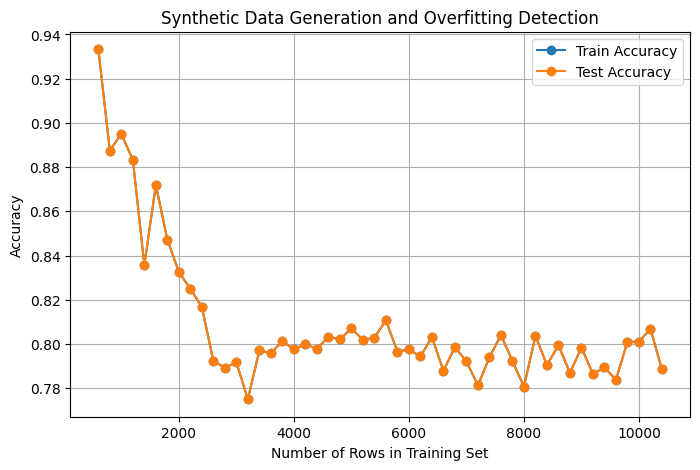

In [ ]:
# Plot overfitting detection
plt.figure(figsize=(8, 5))
plt.plot(num_rows_generated, train_accuracies, label="Train Accuracy", marker="o")
plt.plot(num_rows_generated, test_accuracies, label="Test Accuracy", marker="o")
plt.xlabel("Number of Rows in Training Set")
plt.ylabel("Accuracy")
plt.title("Synthetic Data Generation and Overfitting Detection")
plt.legend()
plt.grid()
plt.show()

In [ ]:
new_rows = synthesizer.sample(4800)  # Generate 2000 rows
data_synth = pd.concat([data, new_rows]).reset_index(drop=True)

In [ ]:
data_synth.shape

(5200, 26)

In [ ]:
# prompt: export data_synth to csv

data_synth.to_csv('data_synth1.csv', index=False)


In [ ]:
!pip install sdv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.1/156.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.2/139.2 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.4/13.4 MB 84.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.5/68.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.1/179.1 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.2/84.2 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 64.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8

In [ ]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sdv.metadata import SingleTableMetadata
from sdv.single_table import CTGANSynthesizer
from sklearn.preprocessing import LabelEncoder

# Suppress warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Load the dataset
file_path = "kidney_disease.csv"
data = pd.read_csv(file_path)

# Fix inconsistent class labels
data["classification"] = data["classification"].replace({"ckd\t": "ckd"})

# Store original missing value proportions
missing_proportions = data.isnull().mean()

# Handle missing values
for col in data.columns:
    if data[col].dtype == "object":
        data[col].fillna(data[col].mode()[0], inplace=True)
    else:
        data[col].fillna(data[col].mean(), inplace=True)

# Identify categorical columns (excluding classification)
categorical_cols = data.select_dtypes(include=["object"]).columns.tolist()
categorical_cols.remove("classification")  # Keep classification separate

# Encode categorical columns before SMOTE
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le  # Store for decoding later

# Convert classification to numerical mapping
label_map = {"ckd": 1, "notckd": 0}
data["classification"] = data["classification"].map(label_map)

# Separate features and target
X = data.drop(columns=["classification"])
y = data["classification"]

# Apply SMOTE for class balancing
smote = SMOTE(sampling_strategy="auto", random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Convert target variable back to categorical after SMOTE
y_resampled = y_resampled.map({1: "ckd", 0: "notckd"})

# Convert encoded categorical columns back to original values
data_resampled = pd.DataFrame(X_resampled, columns=X.columns)
for col in categorical_cols:
    le = label_encoders[col]
    data_resampled[col] = le.inverse_transform(data_resampled[col])

# Add back classification column
data_resampled["classification"] = y_resampled

# Define metadata with categorical columns
metadata = SingleTableMetadata()
metadata.detect_from_dataframe(data_resampled)

# Explicitly mark categorical columns
for col in categorical_cols + ["classification"]:
    metadata.update_column(column_name=col, sdtype="categorical")

# Train CTGAN with categorical metadata
synthesizer = CTGANSynthesizer(metadata, epochs=500, batch_size=500, generator_dim=(256, 256, 256), discriminator_steps=2)
synthesizer.fit(data_resampled)

print("CTGAN Training Complete!")

# Generate synthetic samples (balanced)
num_ckd = 5000
num_notckd = 5000
new_rows = synthesizer.sample(num_ckd + num_notckd)

# Ensure balanced synthetic class distribution
ckd_synthetic = new_rows[new_rows["classification"] == "ckd"].sample(num_ckd, replace=True, random_state=42)
notckd_synthetic = new_rows[new_rows["classification"] == "notckd"].sample(num_notckd, replace=True, random_state=42)

# Combine and reset index
synthetic_balanced = pd.concat([ckd_synthetic, notckd_synthetic]).reset_index(drop=True)

# Reintroduce missing values in the same proportion as the original dataset
for col in synthetic_balanced.columns:
    missing_count = int(missing_proportions[col] * len(synthetic_balanced))
    missing_indices = np.random.choice(synthetic_balanced.index, missing_count, replace=False)
    synthetic_balanced.loc[missing_indices, col] = np.nan

# Verify class distribution
print("Final Synthetic Data Class Distribution:")
print(synthetic_balanced["classification"].value_counts())

# **Save dataset while preserving categorical values**
synthetic_balanced.to_csv("data_synth_balanced10kk.csv", index=False)
print("Balanced synthetic dataset saved as 'data_synth_balanced.csv'")


CTGAN Training Complete!
Final Synthetic Data Class Distribution:
classification
ckd       5000
notckd    5000
Name: count, dtype: int64
Balanced synthetic dataset saved as 'data_synth_balanced.csv'


In [ ]:
!pip install -q sdv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

!pip install sdv
from sdv.single_table import CTGANSynthesizer
from sdv.metadata import SingleTableMetadata

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

import warnings

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


# ============================================================
# 1. LOAD DATASET
# ============================================================

from google.colab import files

uploaded = files.upload()

file_path = "kidney_disease.csv"
data = pd.read_csv(file_path)


# ============================================================
# 2. RENAME COLUMNS
# ============================================================

column_mapping = {
    'age': 'age',
    'bp': 'blood_pressure',
    'sg': 'specific_gravity',
    'al': 'albumin',
    'su': 'sugar',
    'rbc': 'red_blood_cells',
    'pc': 'pus_cell',
    'pcc': 'pus_cell_clumps',
    'ba': 'bacteria',
    'bgr': 'blood_glucose_random',
    'bu': 'blood_urea',
    'sc': 'serum_creatinine',
    'sod': 'sodium',
    'pot': 'potassium',
    'hemo': 'hemoglobin',
    'pcv': 'packed_cell_volume',
    'wc': 'white_blood_cell_count',
    'rc': 'red_blood_cell_count',
    'htn': 'hypertension',
    'dm': 'diabetes_mellitus',
    'cad': 'coronary_artery_disease',
    'appet': 'appetite',
    'pe': 'pedal_edema',
    'ane': 'anemia',
    'classification': 'class'
}

data.rename(columns=column_mapping, inplace=True)


# ============================================================
# 3. STANDARDIZE CLASS VALUES
# ============================================================

data["class"] = data["class"].replace({
    "ckd\t": "ckd",
    "ckd": "ckd",
    "notckd": "notckd",
    "not ckd": "notckd",
    "normal": "notckd"
})


# ============================================================
# 4. DEFINE COLUMN TYPES
# ============================================================

categorical_cols = [
    "red_blood_cells",
    "pus_cell",
    "pus_cell_clumps",
    "bacteria",
    "hypertension",
    "diabetes_mellitus",
    "coronary_artery_disease",
    "appetite",
    "pedal_edema",
    "anemia",
    "class"
]

numerical_cols = [
    "age",
    "blood_pressure",
    "specific_gravity",
    "albumin",
    "sugar",
    "blood_glucose_random",
    "blood_urea",
    "serum_creatinine",
    "sodium",
    "potassium",
    "hemoglobin",
    "packed_cell_volume",
    "white_blood_cell_count",
    "red_blood_cell_count"
]


# ============================================================
# 5. PRESERVE THE ORIGINAL 400 RECORDS
# ============================================================

# This copy is retained for the final dataset.
# No LabelEncoder is applied to it.

original_data = data.copy()


# ============================================================
# 6. CREATE CLEAN TRAINING COPY FOR CTGAN
# ============================================================

ctgan_data = data.copy()


# Convert numerical columns to numeric
for col in numerical_cols:
    ctgan_data[col] = pd.to_numeric(
        ctgan_data[col],
        errors="coerce"
    )


# Convert categorical columns to strings
for col in categorical_cols:
    ctgan_data[col] = ctgan_data[col].astype("object")


# ============================================================
# 7. HANDLE MISSING VALUES ONLY IN CTGAN TRAINING DATA
# ============================================================

# Numerical columns → mean
for col in numerical_cols:
    if ctgan_data[col].isna().any():
        ctgan_data[col] = ctgan_data[col].fillna(
            ctgan_data[col].mean()
        )


# Categorical columns → mode
for col in categorical_cols:
    if ctgan_data[col].isna().any():

        mode_value = ctgan_data[col].mode()

        if len(mode_value) > 0:
            ctgan_data[col] = ctgan_data[col].fillna(
                mode_value.iloc[0]
            )
        else:
            ctgan_data[col] = ctgan_data[col].fillna("unknown")


# ============================================================
# 8. CREATE SDV METADATA
# ============================================================

metadata = SingleTableMetadata()

metadata.detect_from_dataframe(ctgan_data)


# Explicitly configure categorical columns
for col in categorical_cols:
    metadata.update_column(
        column_name=col,
        sdtype="categorical"
    )


# Explicitly configure numerical columns
for col in numerical_cols:
    metadata.update_column(
        column_name=col,
        sdtype="numerical"
    )


# ============================================================
# 9. DISPLAY METADATA
# ============================================================

print("\n================ METADATA ================\n")

for col in ctgan_data.columns:
    print(
        f"{col:30s} -> "
        f"{metadata.columns[col]['sdtype']}"
    )


# ============================================================
# 10. TRAIN CTGAN
# ============================================================

synthesizer = CTGANSynthesizer(
    metadata,
    epochs=500,
    batch_size=200,
    generator_dim=(256, 256, 256),
    discriminator_steps=2
)

print("\nTraining CTGAN...")
synthesizer.fit(ctgan_data)

print("\nCTGAN Training Complete!")


# ============================================================
# 11. TARGET DATASET SIZE
# ============================================================

TOTAL_TARGET_RECORDS = 10000

ORIGINAL_RECORDS = len(original_data)

SYNTHETIC_RECORDS_REQUIRED = (
    TOTAL_TARGET_RECORDS - ORIGINAL_RECORDS
)

print("\n==========================================")
print("DATASET SIZE PLAN")
print("==========================================")
print("Original records :", ORIGINAL_RECORDS)
print("Synthetic needed :", SYNTHETIC_RECORDS_REQUIRED)
print("Final target     :", TOTAL_TARGET_RECORDS)
print("==========================================\n")


# ============================================================
# 12. GENERATE EXACTLY 9,600 SYNTHETIC RECORDS
# ============================================================

synthetic_parts = []

remaining = SYNTHETIC_RECORDS_REQUIRED

batch_size = 200

iteration = 0


while remaining > 0:

    iteration += 1

    current_batch_size = min(
        batch_size,
        remaining
    )

    new_rows = synthesizer.sample(
        num_rows=current_batch_size
    )

    synthetic_parts.append(new_rows)

    remaining -= current_batch_size

    generated_so_far = (
        SYNTHETIC_RECORDS_REQUIRED - remaining
    )

    print(
        f"Synthetic generation "
        f"{iteration:02d}: "
        f"{generated_so_far}/{SYNTHETIC_RECORDS_REQUIRED}"
    )


# Combine all synthetic batches
synthetic_data = pd.concat(
    synthetic_parts,
    ignore_index=True
)


# ============================================================
# 13. SAFETY CHECK — EXACTLY 9,600 SYNTHETIC ROWS
# ============================================================

assert len(synthetic_data) == SYNTHETIC_RECORDS_REQUIRED

print("\nSynthetic records generated:",
      len(synthetic_data))


# ============================================================
# 14. FINAL DATASET
# ============================================================

data_copy = pd.concat(
    [
        original_data,
        synthetic_data
    ],
    ignore_index=True
)


# ============================================================
# 15. FINAL DATASET SIZE CHECK
# ============================================================

print("\n==========================================")
print("FINAL DATASET")
print("==========================================")

print("Original records :", len(original_data))
print("Synthetic records:", len(synthetic_data))
print("Total records    :", len(data_copy))

print("==========================================\n")


assert len(original_data) == 400
assert len(synthetic_data) == 9600
assert len(data_copy) == 10000


# ============================================================
# 16. CHECK DATA TYPES
# ============================================================

print("\n================ DATA TYPES ================\n")

print(data_copy.dtypes)


# ============================================================
# 17. CHECK CATEGORICAL VALUES
# ============================================================

print("\n========== CATEGORICAL VALUES ==========\n")

for col in categorical_cols:

    print(f"\n{col}:")

    print(
        data_copy[col]
        .dropna()
        .unique()
    )


# ============================================================
# 18. RANDOM FOREST EVALUATION
# ============================================================

# Random Forest requires numerical inputs.
# Therefore, encoding is performed ONLY on a temporary
# evaluation copy. It does NOT alter the final CSV.

evaluation_data = data_copy.copy()

evaluation_encoders = {}

for col in categorical_cols:

    if col == "class":
        continue

    evaluation_data[col] = (
        evaluation_data[col]
        .astype(str)
    )

    categories = (
        evaluation_data[col]
        .unique()
        .tolist()
    )

    mapping = {
        value: index
        for index, value in enumerate(categories)
    }

    evaluation_data[col] = (
        evaluation_data[col]
        .map(mapping)
    )

    evaluation_encoders[col] = mapping


# Encode target only for model evaluation
class_mapping = {
    "notckd": 0,
    "ckd": 1
}

evaluation_data["class"] = (
    evaluation_data["class"]
    .map(class_mapping)
)


# Make sure numerical columns are numeric
for col in numerical_cols:

    evaluation_data[col] = pd.to_numeric(
        evaluation_data[col],
        errors="coerce"
    )


# Fill any remaining missing values for evaluation
for col in evaluation_data.columns:

    if evaluation_data[col].isna().any():

        evaluation_data[col] = (
            evaluation_data[col]
            .fillna(evaluation_data[col].median())
        )


# ============================================================
# 19. TRAIN / TEST SPLIT
# ============================================================

X = evaluation_data.drop(
    columns=["class"]
)

y = evaluation_data["class"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ============================================================
# 20. RANDOM FOREST
# ============================================================

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(
    X_train,
    y_train
)


# ============================================================
# 21. EVALUATION
# ============================================================

train_predictions = model.predict(X_train)

test_predictions = model.predict(X_test)


train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)


print("\n==========================================")
print("RANDOM FOREST EVALUATION")
print("==========================================")

print(
    f"Training Accuracy: "
    f"{train_accuracy:.4f}"
)

print(
    f"Testing Accuracy : "
    f"{test_accuracy:.4f}"
)

print("==========================================\n")


# ============================================================
# 22. SAVE FINAL DATASET
# ============================================================

output_file = (
    "ckd_real_400_plus_synthetic_9600_total_10000.csv"
)

data_copy.to_csv(
    output_file,
    index=False
)


# ============================================================
# 23. FINAL VERIFICATION
# ============================================================

print("File saved successfully!")

print("\nFinal verification:")
print("-------------------")

print(
    "Original rows :",
    len(original_data)
)

print(
    "Synthetic rows:",
    len(synthetic_data)
)

print(
    "Total rows    :",
    len(data_copy)
)

print(
    "\nOutput file:",
    output_file
)


# ============================================================
# 24. DOWNLOAD FILE
# ============================================================

files.download(output_file)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.5/215.5 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.9/259.9 kB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 80.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 8.3 MB/s eta 0:00:00


Saving kidney_disease.csv to kidney_disease.csv

================ METADATA ================

id                             -> id
age                            -> numerical
blood_pressure                 -> numerical
specific_gravity               -> numerical
albumin                        -> numerical
sugar                          -> numerical
red_blood_cells                -> categorical
pus_cell                       -> categorical
pus_cell_clumps                -> categorical
bacteria                       -> categorical
blood_glucose_random           -> numerical
blood_urea                     -> numerical
serum_creatinine               -> numerical
sodium                         -> numerical
potassium                      -> numerical
hemoglobin                     -> numerical
packed_cell_volume             -> numerical
white_blood_cell_count         -> numerical
red_blood_cell_count           -> numerical
hypertension                   -> categorical
diabetes_mellitus       

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

# ============================================================
# 1. INSTALL AND IMPORT LIBRARIES
# ============================================================
%pip install -U sdv

import numpy as np
import pandas as pd
import sdv
import warnings

from google.colab import files
from sdv.metadata import Metadata
from sdv.single_table import CTGANSynthesizer

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

print("SDV version:", sdv.__version__)

# ============================================================
# 2. UPLOAD AND LOAD DATASET
# ============================================================
uploaded = files.upload()
file_path = next(iter(uploaded))

data = pd.read_csv(file_path)

print("Original dataset shape:", data.shape)

# ============================================================
# 3. RENAME COLUMNS
# ============================================================
column_mapping = {
    "bp": "blood_pressure",
    "sg": "specific_gravity",
    "al": "albumin",
    "su": "sugar",
    "rbc": "red_blood_cells",
    "pc": "pus_cell",
    "pcc": "pus_cell_clumps",
    "ba": "bacteria",
    "bgr": "blood_glucose_random",
    "bu": "blood_urea",
    "sc": "serum_creatinine",
    "sod": "sodium",
    "pot": "potassium",
    "hemo": "hemoglobin",
    "pcv": "packed_cell_volume",
    "wc": "white_blood_cell_count",
    "rc": "red_blood_cell_count",
    "htn": "hypertension",
    "dm": "diabetes_mellitus",
    "cad": "coronary_artery_disease",
    "appet": "appetite",
    "pe": "pedal_edema",
    "ane": "anemia",
    "classification": "class"
}

data.rename(columns=column_mapping, inplace=True)

# Remove identifier column, if present
if "id" in data.columns:
    data.drop(columns=["id"], inplace=True)

# ============================================================
# 4. CLEAN TEXT AND MISSING VALUES
# ============================================================
data.replace(r"^\s*$", np.nan, regex=True, inplace=True)
data.replace(r"^\s*\?\s*$", np.nan, regex=True, inplace=True)

# Strip leading/trailing whitespace from text
for col in data.select_dtypes(include=["object", "string"]).columns:
    data[col] = data[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardize target labels
data["class"] = (
    data["class"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "ckd\t": "ckd",
        "normal": "notckd",
        "abnormal": "ckd"
    })
)

# ============================================================
# 5. DEFINE NUMERIC AND CATEGORICAL COLUMNS
# ============================================================
numeric_cols = [
    "age",
    "blood_pressure",
    "blood_glucose_random",
    "blood_urea",
    "serum_creatinine",
    "sodium",
    "potassium",
    "hemoglobin",
    "packed_cell_volume",
    "white_blood_cell_count",
    "red_blood_cell_count"
]

categorical_cols = [
    "specific_gravity",
    "albumin",
    "sugar",
    "red_blood_cells",
    "pus_cell",
    "pus_cell_clumps",
    "bacteria",
    "hypertension",
    "diabetes_mellitus",
    "coronary_artery_disease",
    "appetite",
    "pedal_edema",
    "anemia",
    "class"
]

# Check that expected columns exist
expected_cols = numeric_cols + categorical_cols
missing_cols = [c for c in expected_cols if c not in data.columns]

if missing_cols:
    raise ValueError(f"Expected columns are missing: {missing_cols}")

# Convert continuous measurements to numeric
for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Keep categorical values as strings
for col in categorical_cols:
    data[col] = data[col].astype("string")

# ============================================================
# 6. FILL MISSING VALUES BEFORE CTGAN TRAINING
# ============================================================
for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

for col in categorical_cols:
    modes = data[col].mode(dropna=True)

    if modes.empty:
        raise ValueError(
            f"Column '{col}' contains no valid category values."
        )

    data[col] = data[col].fillna(modes.iloc[0])

if data.isnull().any().any():
    raise ValueError("Missing values remain after cleaning.")

# Confirm target labels
valid_classes = {"ckd", "notckd"}
found_classes = set(data["class"].astype(str).unique())

if not found_classes.issubset(valid_classes):
    raise ValueError(
        f"Unexpected target labels found: {found_classes}"
    )

print("\nCleaned dataset shape:", data.shape)
print("\nTarget distribution:")
print(data["class"].value_counts())

# ============================================================
# 7. CREATE METADATA FOR SDV 2.0.0
# ============================================================
metadata = Metadata()
metadata.add_table("ckd")

for col in data.columns:

    if col in categorical_cols:
        sdtype = "categorical"
    else:
        sdtype = "numerical"

    metadata.add_column(
        column_name=col,
        sdtype=sdtype,
        table_name="ckd"
    )

metadata.validate()

print("\nMetadata created and validated successfully.")

# ============================================================
# 8. TRAIN CTGAN
# ============================================================
synthesizer = CTGANSynthesizer(
    metadata=metadata,
    epochs=500,
    batch_size=500,
    generator_dim=(256, 256, 256),
    discriminator_steps=2,
    verbose=True
)

# SDV 2.0.0 single-table API:
# supply a dictionary keyed by table name
synthesizer.fit({
    "ckd": data
})

print("\nCTGAN training completed successfully!")

# ============================================================
# 9. GENERATE EXACTLY 10,000 SYNTHETIC RECORDS
# ============================================================
sampled_data = synthesizer.sample(num_rows=10000)

# Extract the generated table
synthetic_data = sampled_data["ckd"]

if len(synthetic_data) != 10000:
    raise ValueError(
        f"Expected 10,000 rows, received {len(synthetic_data)}."
    )

print("\nSynthetic dataset shape:", synthetic_data.shape)

# ============================================================
# 10. CHECK CATEGORICAL VALUES
# ============================================================
print("\n========== CATEGORICAL VALUE CHECK ==========")

for col in categorical_cols:

    original_values = set(data[col].dropna().astype(str))
    generated_values = set(
        synthetic_data[col].dropna().astype(str)
    )

    unexpected = generated_values - original_values

    print(f"\nColumn: {col}")
    print("Generated categories:", sorted(generated_values))

    if unexpected:
        print("WARNING - Unexpected categories:", unexpected)
    else:
        print("All generated categories occur in the source data.")

# ============================================================
# 11. PRESERVE CATEGORICAL TEXT IN OUTPUT
# ============================================================
for col in categorical_cols:
    synthetic_data[col] = synthetic_data[col].astype("string")

# Do not apply LabelEncoder to this exported dataset.

# ============================================================
# 12. EXPORT SYNTHETIC DATA ONLY
# ============================================================
output_file = "ckd_synthetic_10000.csv"

synthetic_data.to_csv(
    output_file,
    index=False
)

# ============================================================
# 13. VERIFY THE SAVED FILE
# ============================================================
check_data = pd.read_csv(output_file)

print("\n========== FINAL VERIFICATION ==========")
print("Original training records:", len(data))
print("Synthetic records generated:", len(synthetic_data))
print("Records in exported CSV:", len(check_data))
print("Number of columns:", len(check_data.columns))

assert len(synthetic_data) == 10000
assert len(check_data) == 10000

print("\nExport verified: exactly 10,000 synthetic records.")
print("Saved file:", output_file)

print("\nGenerated target distribution:")
print(check_data["class"].value_counts())

# ============================================================
# 14. DOWNLOAD THE CSV
# ============================================================
files.download(output_file)


SDV version: 2.0.0


Saving kidney_disease.csv to kidney_disease (5).csv
Original dataset shape: (400, 26)

Cleaned dataset shape: (400, 25)

Target distribution:
class
ckd       250
notckd    150
Name: count, dtype: Int64

Metadata created and validated successfully.


Gen. (-00.90) | Discrim. (-00.70): 100%|██████████| 500/500 [02:25<00:00,  3.43it/s]



CTGAN training completed successfully!

Synthetic dataset shape: (10000, 25)

========== CATEGORICAL VALUE CHECK ==========

Column: specific_gravity
Generated categories: ['1.005', '1.01', '1.015', '1.02', '1.025']
All generated categories occur in the source data.

Column: albumin
Generated categories: ['0.0', '1.0', '2.0', '3.0', '4.0', '5.0']
All generated categories occur in the source data.

Column: sugar
Generated categories: ['0.0', '1.0', '2.0', '3.0', '4.0', '5.0']
All generated categories occur in the source data.

Column: red_blood_cells
Generated categories: ['abnormal', 'normal']
All generated categories occur in the source data.

Column: pus_cell
Generated categories: ['abnormal', 'normal']
All generated categories occur in the source data.

Column: pus_cell_clumps
Generated categories: ['notpresent', 'present']
All generated categories occur in the source data.

Column: bacteria
Generated categories: ['notpresent', 'present']
All generated categories occur in the sourc

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>